# **[모의] 딥러닝 중간고사 : 이 쥬피터 노트북을 문제에 따라 작성하여 수행 한 후, 노트북을 다운로드하여 제출 하시오.**

* ⚠️**작년 같은 교수님 중간고사 형식을 따라 만든 연습용 노트북**⚠️
* 🔥**채팅(ChatGPT·Gemini 등 AI)이나 다른 사람의 도움을 받지 않는다**🔥
* 🔴**인터넷, 교재 등 자료는 참고 가능. 단, 복사·붙여넣기 하지 말고 이해한 뒤 본인의 말로 작성**🔴
* **문항의 코드 블록 코멘트를 따라 수행하며, 필요하면 블록을 더 추가하여 작성**
* **이론 답안은 Markdown 또는 `<pre>`와 `</pre>` 사이에 작성**

**답안은** 논리적으로 · 꼭 필요한 내용만 · 간결하게, 남에게 설명하듯 작성

학번: 2024551004  이름: 김동민

In [1]:
# 공통 import (먼저 실행)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
np.random.seed(42)
tf.random.set_seed(42)

# 1. 심층 신경망에서 그레이디언트 소실(Vanishing Gradient)이 무엇인지, 왜 생기는지, 해결 방법 3가지를 설명하시오.

**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
그레이디언트 소실: 역전파로 출력층에서 입력층 쪽으로 기울기를 전달할 때,
아래층으로 갈수록 기울기가 0에 가까워져 앞쪽 층의 가중치가 거의 갱신되지 않는 현상.

원인: sigmoid의 도함수는 최대 0.25이고 입력이 크거나 작으면 0에 가까워진다(포화).
체인 룰로 층마다 이 값이 곱해지므로 층이 깊을수록 기울기가 기하급수적으로 작아진다.
또 층을 지날수록 출력의 평균·분산이 입력과 달라지는 것도 원인이다.

해결 방법
1) 초기화: 층의 입력·출력 분산이 비슷하도록 가중치를 초기화 (ReLU에는 He, sigmoid·tanh에는 Glorot)
2) 활성화 함수: 양수에서 포화되지 않는 ReLU 계열 사용 (죽은 ReLU는 LeakyReLU·ELU로 완화)
3) 배치 정규화: 층마다 미니배치 단위로 평균 0, 분산 1로 맞춘 뒤 γ, β로 조정
</pre>

# 2. 주어진 Salary2024.csv를 업로드하여, Pandas를 이용하여 다음을 구하시오.

### a. 경력 수준(experience_level)별 연봉(salary_in_usd)의 최소, 최대, 평균을 구하고, 평균이 높은 순으로 정렬하시오.

In [2]:
# a. 경력 수준별 연봉 최소·최대·평균, 평균 내림차순
datafile = '/content/Salary2024.csv'
df = pd.read_csv(datafile)
result_a = df.groupby('experience_level')['salary_in_usd'].agg(['min', 'max', 'mean'])
result_a = result_a.sort_values(by='mean', ascending=False)     # 정렬 결과를 다시 저장해야 반영됨
result_a

,min,max,mean
experience_level,,,
Executive-level,15000,465000,189687.346457
Senior-level,15809,750000,162071.063581
Mid-level,15000,750000,119019.812537
Entry-level,15000,350000,84448.916814


### b. 2024년 데이터만으로 직종(job_title)별 평균 연봉 상위 10개를 구하시오.

In [3]:
# b. 2024년 직종별 평균 연봉 상위 10개
df_2024 = df[df['work_year'] == 2024]                               # 2024년만 먼저 거르기
result_b = df_2024.groupby('job_title')['salary_in_usd'].mean()
result_b.sort_values(ascending=False).head(10)

job_title
Machine Learning Scientist        282916.666667
Managing Director Data Science    260000.000000
AI Architect                      229662.500000
Research Engineer                 227896.782609
Applied Scientist                 222618.875000
ML Engineer                       222600.000000
Data Product Manager              213150.000000
Computer Vision Engineer          210000.000000
Research Scientist                207876.190476
Director of Data Science          202500.000000
Name: salary_in_usd, dtype: float64

# 3. 다음 사양의 신경망으로 Fashion MNIST를 학습하고 테스트 정확도와 학습 곡선을 출력하시오.

Hidden Layer
* 300개, 100개의 2개의 Hidden
* Activation: ELU
* Initializer: He
* 각 Hidden 다음에 배치 정규화 적용
* Optimizer: NAG (learning_rate 0.01, momentum 0.9)

Output Layer
* Activation: Softmax

학습: 10 epoch, 검증 세트 5,000개

In [4]:
# 데이터 로딩, 정규화(0~1), 학습/검증 분리
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.
print(X_train.shape, X_valid.shape, X_test.shape)

(55000, 28, 28) (5000, 28, 28) (10000, 28, 28)


In [5]:
# 모델 생성 및 summary
model = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation="elu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300)            │         1,200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,210 (1.02 MB)

 Trainable params: 267,410 (1.02 MB)

 Non-trainable params: 800 (3.12 KB)

In [6]:
# 컴파일, 학습
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
              metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid), verbose=2)

Epoch 1/10


1719/1719 - 9s - 5ms/step - accuracy: 0.8318 - loss: 0.4711 - val_accuracy: 0.8598 - val_loss: 0.3841


Epoch 2/10


1719/1719 - 10s - 6ms/step - accuracy: 0.8681 - loss: 0.3627 - val_accuracy: 0.8688 - val_loss: 0.3630


Epoch 3/10


...

1719/1719 - 7s - 4ms/step - accuracy: 0.9287 - loss: 0.2004 - val_accuracy: 0.8670 - val_loss: 0.3808


Epoch 9/10


1719/1719 - 8s - 5ms/step - accuracy: 0.9355 - loss: 0.1815 - val_accuracy: 0.8614 - val_loss: 0.3998


Epoch 10/10


1719/1719 - 11s - 6ms/step - accuracy: 0.9419 - loss: 0.1640 - val_accuracy: 0.8536 - val_loss: 0.4455


  1/313 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.7812 - loss: 0.8330

 22/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8338 - loss: 0.5442 

 44/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8487 - loss: 0.5218

 72/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8559 - loss: 0.4664

 96/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8493 - loss: 0.4975

...

256/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8496 - loss: 0.5009

279/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8501 - loss: 0.4980

303/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8491 - loss: 0.4972

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8502 - loss: 0.4944


테스트 정확도: 0.8502


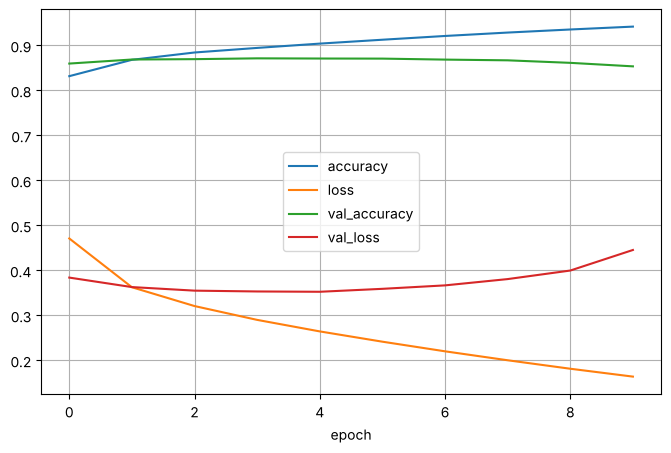

In [7]:
# 테스트 정확도, 학습 곡선
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"테스트 정확도: {test_acc:.4f}")
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True); plt.xlabel("epoch"); plt.show()

### 위 모델에서 BatchNormalization 층의 파라미터 수가 Dense(300) 뒤에서 1,200개인 이유와, 그중 훈련되지 않는 파라미터가 무엇인지 설명하시오.

**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
BatchNormalization은 입력 특성(뉴런) 하나마다 4개의 파라미터를 가진다.
Dense(300) 뒤이므로 300 × 4 = 1,200개.

- γ(스케일), β(이동): 역전파로 학습되는 파라미터
- 이동 평균, 이동 분산: 학습 중 배치 통계를 누적해 두었다가 테스트(예측) 때 쓰는 값으로,
  역전파로 학습되지 않는다 (Non-trainable)
</pre>

# 4. 옵티마이저 비교

같은 모델(Flatten → Dense(300, relu) → Dense(100, relu) → Dense(10, softmax))로
SGD(lr 0.01), Momentum(lr 0.01, 0.9), Adam(lr 0.001)을 각각 5 epoch 학습하여

**a)** 검증 손실(val_loss) 곡선을 한 그래프에 그리고, 테스트 정확도를 표로 정리하시오.

**b)** 결과를 근거로 세 옵티마이저의 차이를 설명하시오.

In [8]:
# 모델을 만드는 함수
def build_model():
    return keras.models.Sequential([
        keras.layers.Input(shape=[28, 28]),
        keras.layers.Flatten(),
        keras.layers.Dense(300, activation="relu"),
        keras.layers.Dense(100, activation="relu"),
        keras.layers.Dense(10, activation="softmax")
    ])

# 옵티마이저별 학습
optimizers = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "Momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),
}
histories, results = {}, {}
for name, make_opt in optimizers.items():
    m = build_model()
    m.compile(loss="sparse_categorical_crossentropy", optimizer=make_opt(), metrics=["accuracy"])
    histories[name] = m.fit(X_train, y_train, epochs=5, validation_data=(X_valid, y_valid), verbose=0)
    results[name] = m.evaluate(X_test, y_test, verbose=0)[1]

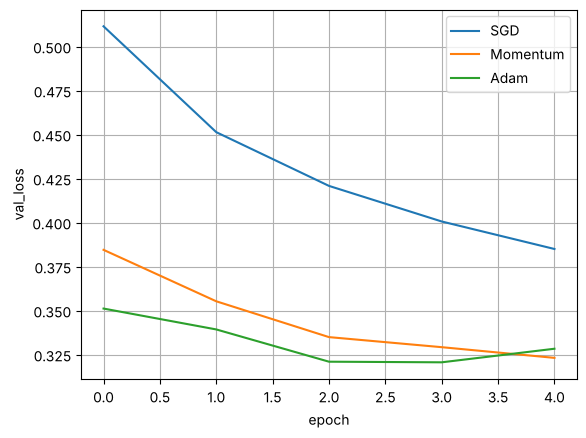

,test_accuracy
Momentum,0.8677
Adam,0.8658
SGD,0.8458


In [9]:
# val_loss 그래프, 테스트 정확도 표
for name, h in histories.items():
    plt.plot(h.history["val_loss"], label=name)
plt.xlabel("epoch"); plt.ylabel("val_loss"); plt.legend(); plt.grid(True); plt.show()
pd.DataFrame({"test_accuracy": results}).sort_values("test_accuracy", ascending=False)

**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
(정확도 숫자는 실행 결과를 보고 채운다)
- SGD: 배치마다 기울기만큼만 이동해서 같은 5 epoch 동안 손실이 가장 천천히 줄었다.
- Momentum: 이전 이동 방향을 관성처럼 누적해 같은 방향이면 더 크게 이동 → SGD보다 빨리 수렴.
- Adam: Momentum(기울기의 지수 평균) + RMSProp(기울기 제곱의 지수 평균으로 방향별 학습률 조정)
  + 초기 편향 보정. 학습률을 자동으로 조정해 적은 epoch에서도 손실이 빠르게 줄었다.
결론: 같은 epoch이면 관성·적응형 옵티마이저가 SGD보다 빨리 수렴한다.
SGD는 느리지만 오래 학습하면 최종 품질은 좋을 수 있다.
</pre>

# 5. CNN

**a)** 아래 구조의 CNN을 만들어 Fashion MNIST를 5 epoch 학습하고 테스트 정확도를 구하시오.

Conv2D(32, 3×3, same) → MaxPooling2D(2×2) → Conv2D(64, 3×3, same) → MaxPooling2D(2×2) → Flatten → Dense(128, relu) → Dropout(0.2) → Dense(10, softmax), Optimizer: nadam

**b)** 첫 번째 Conv2D의 파라미터가 320개, 두 번째가 18,496개인 이유를 계산식으로 설명하시오.

**c)** 3번의 Dense 신경망과 비교하여, 이미지에서 CNN이 유리한 이유를 설명하시오.

In [10]:
# CNN 입력은 채널 차원이 필요 (28, 28) → (28, 28, 1)
X_train_c, X_valid_c, X_test_c = X_train[..., np.newaxis], X_valid[..., np.newaxis], X_test[..., np.newaxis]
print(X_train_c.shape)

(55000, 28, 28, 1)


In [11]:
# CNN 모델 생성, 학습, 평가
cnn = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28, 1]),
    keras.layers.Conv2D(32, kernel_size=(3, 3), padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(64, kernel_size=(3, 3), padding="same"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation="softmax")
])
cnn.summary()
cnn.compile(loss="sparse_categorical_crossentropy", optimizer="nadam", metrics=["accuracy"])
cnn.fit(X_train_c, y_train, epochs=5, validation_data=(X_valid_c, y_valid), verbose=2)
print("CNN 테스트 정확도:", cnn.evaluate(X_test_c, y_test, verbose=0)[1])

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 4/5


1719/1719 - 27s - 15ms/step - accuracy: 0.9245 - loss: 0.2029 - val_accuracy: 0.9192 - val_loss: 0.2356


Epoch 5/5


1719/1719 - 25s - 15ms/step - accuracy: 0.9342 - loss: 0.1738 - val_accuracy: 0.9128 - val_loss: 0.2595


CNN 테스트 정확도: 0.9082000255584717


**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
b) Conv2D 파라미터 = (커널 높이 × 커널 너비 × 입력 채널 + 편향 1) × 필터 수
- 첫 번째: 입력 채널 1 → (3×3×1 + 1) × 32 = 10 × 32 = 320
- 두 번째: 입력 채널은 앞 층의 필터 수 32 → (3×3×32 + 1) × 64 = 289 × 64 = 18,496

c) Dense 신경망은 28×28 그림을 784개 한 줄로 펴서 입력하므로 픽셀 사이의 위치 관계가 사라진다.
CNN은 그림 모양 그대로 작은 필터를 이동시키며 주변 픽셀을 함께 보므로 선·모서리 같은 지역 특징을 잡고,
같은 필터를 이미지 전체에 공유해 파라미터가 적다. 풀링으로 크기를 줄여 위치가 조금 달라도 같은 결과를 낸다.
</pre>

# 6. 텐서플로 자동 미분

함수 z = 3·w1² + 2·w1·w2 에서 (w1, w2) = (5, 3)일 때의 기울기를

**a)** 손으로 편미분한 식으로 구하고 (`<pre>`에 작성)

**b)** `tf.GradientTape`로 구해서 같은지 확인하시오.

**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
∂z/∂w1 = 6·w1 + 2·w2 = 6×5 + 2×3 = 36
∂z/∂w2 = 2·w1 = 2×5 = 10
→ 기울기 (36, 10)
</pre>

In [12]:
# GradientTape로 기울기 구하기
w1, w2 = tf.Variable(5.), tf.Variable(3.)        # constant면 기록되지 않음
with tf.GradientTape() as tape:
    z = 3 * w1 ** 2 + 2 * w1 * w2
print(tape.gradient(z, [w1, w2]))

[<tf.Tensor: shape=(), dtype=float32, numpy=36.0>, <tf.Tensor: shape=(), dtype=float32, numpy=10.0>]


# 7. 과대적합(Overfitting)이 무엇인지 설명하고, 학습 곡선에서 어떻게 알아볼 수 있는지와 방지 방법 3가지를 쓰시오.

**주의** : 아래 `<pre>`와 `</pre>`사이에 답안을 작성 하시요.

<pre>
과대적합: 모델이 훈련 데이터에 지나치게 맞춰져 새로운 데이터(검증·테스트)에서 성능이 떨어지는 상태.

학습 곡선: 훈련 손실(loss)은 계속 줄어드는데 검증 손실(val_loss)이 줄지 않거나 다시 올라가면
과대적합이 시작된 것이다. 훈련 정확도와 검증 정확도의 차이가 벌어진다.

방지 방법
1) 드롭아웃: 학습 중 뉴런 일부를 랜덤하게 꺼서 특정 뉴런에 의존하지 않게 함
2) L1/L2 규제: 큰 가중치에 벌점을 주어 모델을 단순하게 유지
3) 조기 종료: 검증 손실이 더 나아지지 않으면 학습을 멈추고 가장 좋았던 가중치로 되돌림
(그 외: 데이터 증강, 모델 크기 줄이기)
</pre>

---
### 제출 전
* 런타임 → **다시 시작 및 모두 실행** → 에러 없이 끝까지 실행되는지 확인
* 파일 → 다운로드 → **.ipynb 다운로드** → 제출